<a href="https://colab.research.google.com/github/rifqiraehan/modellationis-simulationis/blob/main/WPSV_Metode_Simulasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from IPython.display import HTML, display

def set_css():
  display(HTML('''

  '''))
get_ipython().events.register('pre_run_cell', set_css)

In [ ]:
!pip install numpy matplotlib scipy

## 3. Monte Carlo Simulation

Materi menjelaskan Monte Carlo sebagai sampling acak berulang untuk memperkirakan besaran atau menganalisis sistem kompleks. Prosesnya meliputi probabilitas, probabilitas kumulatif, interval random, random number generation, pengulangan, dan distribusi hasil.

### 3.1 Estimasi Nilai $\pi$

Estimasi pi 3.1256
Error      : 0.015992653589793182


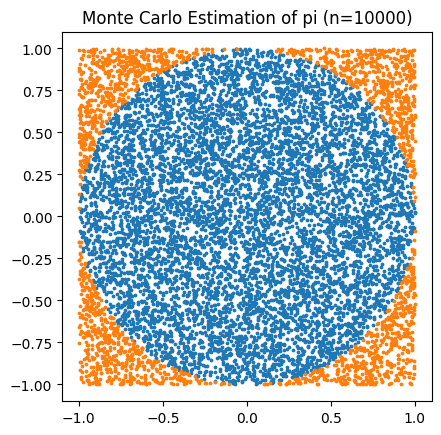

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def estimate_pi(n, seed=42):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1, 1, n)
    y = rng.uniform(-1, 1, n)
    inside = x * x + y * y <= 1
    return 4 * inside.mean(), x, y, inside

n = 10000
pi_est, x, y, inside = estimate_pi(n)
print("Estimasi pi", pi_est)
print("Error      :", abs(np.pi - pi_est))

plt.scatter(x[inside], y[inside], s=3)
plt.scatter(x[~inside], y[~inside], s=3)
plt.gca().set_aspect("equal")
plt.title(f"Monte Carlo Estimation of pi (n={n})")
plt.show()

### Analisa

Pada percobaan estimasi nilai π dengan 10.000 titik acak, diperoleh estimasi π sebesar 3,1256 dengan absolute error 0,01599 atau sekitar 0,51%. Hasil menunjukkan bahwa metode Monte Carlo dapat mengestimasi nilai π dengan cukup mendekati nilai teoritis melalui titik acak di dalam dan di luar lingkaran.

### 3.2 Skenario

| Skenario | Iterasi | Analisis |
| --- | --- | --- |
| A | 100 | Akurasi |
| B | 1.000 | Error |
| C | 10.000 | Stabilitas |
| D | 100.000 | Konvergensi |
| E | 1.000.000 | Efek iterasi besar |

1. Hitung estimasi $\pi$ untuk semua skenario.
2. Hitung absolute error terhadap `np.pi`.
3. Buat grafik iterasi vs error.
4. Jelaskan pengaruh jumlah iterasi.

Estimasi pi 3.1364
Error      : 0.005192653589793039


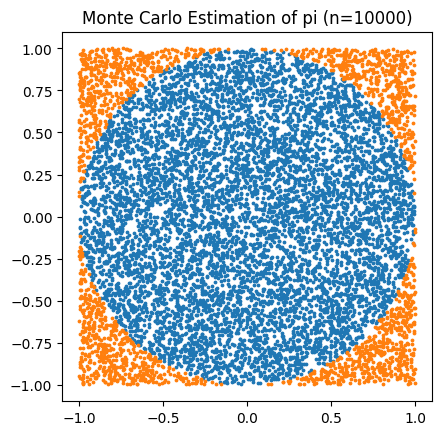

In [ ]:
# Percobaan

import numpy as np
import matplotlib.pyplot as plt

def estimate_pi(n, seed=4):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1, 1, n)
    y = rng.uniform(-1, 1, n)
    inside = x * x + y * y <= 1
    return 4 * inside.mean(), x, y, inside

n = 10000
pi_est, x, y, inside = estimate_pi(n)
print("Estimasi pi", pi_est)
print("Error      :", abs(np.pi - pi_est))

plt.scatter(x[inside], y[inside], s=3)
plt.scatter(x[~inside], y[~inside], s=3)
plt.gca().set_aspect("equal")
plt.title(f"Monte Carlo Estimation of pi (n={n})")
plt.show()

Skenario A
Iterasi  : 100
Estimasi pi : 3.12
Error      : 0.02159265358979301

Skenario B
Iterasi  : 1000
Estimasi pi : 3.08
Error      : 0.061592653589793045

Skenario C
Iterasi  : 10000
Estimasi pi : 3.1256
Error      : 0.015992653589793182

Skenario D
Iterasi  : 100000
Estimasi pi : 3.14308
Error      : 0.001487346410206758

Skenario E
Iterasi  : 1000000
Estimasi pi : 3.14178
Error      : 0.00018734641020667908



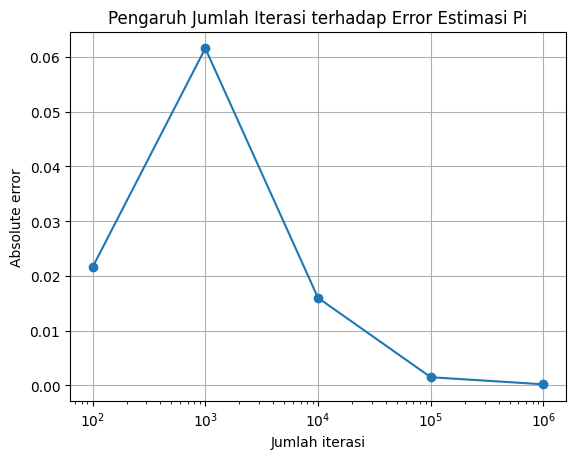

In [ ]:
# Skenario

import numpy as np
import matplotlib.pyplot as plt

def estimate_pi(n, seed=42):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1, 1, n)
    y = rng.uniform(-1, 1, n)
    inside = x * x + y * y <= 1
    return 4 * inside.mean(), x, y, inside

scenarios = {
    "A": 100,
    "B": 1000,
    "C": 10000,
    "D": 100000,
    "E": 1000000
}

results = []

for scenario, n in scenarios.items():
    pi_est, x, y, inside = estimate_pi(n)
    error = abs(np.pi - pi_est)
    results.append((scenario, n, pi_est, error))

    print("Skenario", scenario)
    print("Iterasi  :", n)
    print("Estimasi pi :", pi_est)
    print("Error      :", error)
    print()

iterations = [result[1] for result in results]
errors = [result[3] for result in results]

plt.plot(iterations, errors, marker="o")
plt.xscale("log")
plt.xlabel("Jumlah iterasi")
plt.ylabel("Absolute error")
plt.title("Pengaruh Jumlah Iterasi terhadap Error Estimasi Pi")
plt.grid(True)
plt.show()

### Analisa

Hasil menunjukkan bahwa semakin besar jumlah iterasi, estimasi nilai π cenderung semakin mendekati nilai sebenarnya, yaitu π ≈ 3,14159, dengan nilai error yang semakin kecil.

### 3.3 Dua Dadu - Peluang Jumlah $\ge 10$

In [ ]:
import numpy as np

rng = np.random.default_rng(42)
n = 100000
d1 = rng.integers(1, 7, n)
d2 = rng.integers(1, 7, n)
total = d1 + d2

p_sim = np.mean(total >= 10)
p_theory = 6 / 36

print("Simulasi :", p_sim)
print("Teori    :", p_theory)
print("Error    :", abs(p_sim - p_theory))

Simulasi : 0.16647
Teori    : 0.16666666666666666
Error    : 0.00019666666666665056


Kembangkan menjadi 1.000, 10.000, 100.000, 1.000.000 lemparan dan bandingkan hasil simulasi dengan teori.

In [ ]:
# Pengembangan

import numpy as np

scenarios = [1000, 10000, 100000, 1000000]
p_theory = 6 / 36

print(f"{'Iterasi (n)':<12} | {'Simulasi':<10} | {'Teori':<10} | {'Error':<10}")
print("-" * 50)

for n in scenarios:
    rng = np.random.default_rng(42)
    d1 = rng.integers(1, 7, n)
    d2 = rng.integers(1, 7, n)
    total = d1 + d2

    p_sim = np.mean(total >= 10)
    error = abs(p_sim - p_theory)

    print(f"{n:<12} | {p_sim:<10.5f} | {p_theory:<10.5f} | {error:<10.6f}")


Iterasi (n)  | Simulasi   | Teori      | Error     
--------------------------------------------------
1000         | 0.16200    | 0.16667    | 0.004667  
10000        | 0.16690    | 0.16667    | 0.000233  
100000       | 0.16647    | 0.16667    | 0.000197  
1000000      | 0.16605    | 0.16667    | 0.000614  


### Analisa

Hasil percobaan menunjukkan bahwa peningkatan jumlah lemparan ($n$) dari 1.000 hingga 1.000.000 membuat nilai peluang simulasi (`p_sim`) konvergen mendekati nilai teoretis ($\frac{6}{36} \approx 0.16667$). Hal ini ditunjukkan oleh penurunan selisih absolut (*error*) secara konsisten dari kisaran $10^{-3}$ pada $n = 1.000$ menjadi $10^{-5}$ pada $n = 1.000.000$. Pada percobaan ini, presisi dan akurasi simulasi Monte Carlo ditentukan oleh besarnya ukuran sampel yang digunakan.

## 4. Discrete-Event Simulation (DES)

DES memodelkan perubahan status sistem yang terjadi pada event tertentu. Waktu bergerak dari satu event ke event berikutnya. Materi menggunakan contoh antrian satu loket: interarrival rata-rata 5 menit, service rata-rata 3 menit, durasi 60 menit.

| Elemen | Makna | Contoh |
| --- | --- | --- |
| Entity | Objek diproses | Pelanggan |
| Event | Perubahan status | Arrival / service completion |
| Resource | Fasilitas | Kasir / teller |
| Queue | Tempat menunggu | Antrian |
| Clock | Waktu simulasi | Simulation time |

### 4.1 Program Antrian Satu Loket

Pelanggan: 7
Mean Wq  : 0.5143496073258069
Max Wq   : 2.834883885579991


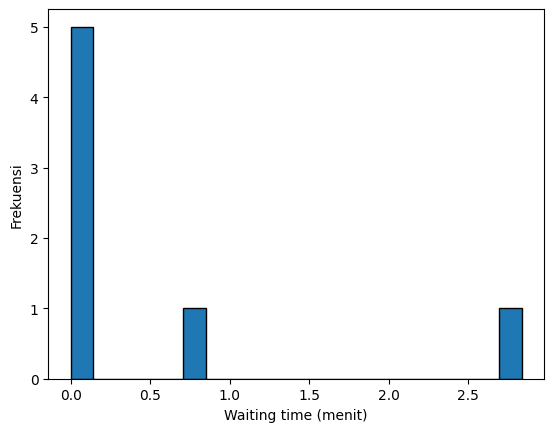

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_queue(lam=1/5, mu=1/3, sim_time=60, seed=42):
    rng = np.random.default_rng(seed)
    arrivals = []
    t = 0
    while True:
        t += rng.exponential(1 / lam)
        if t > sim_time:
            break
        arrivals.append(t)

    free = 0
    waits = []
    services = []
    for a in arrivals:
        st = rng.exponential(1 / mu)
        start = max(a, free)
        waits.append(start - a)
        services.append(st)
        free = start + st

    return np.array(arrivals), np.array(waits), np.array(services)

a, w, s = simulate_queue()
print("Pelanggan:", len(a))
print("Mean Wq  :", w.mean())
print("Max Wq   :", w.max())

plt.hist(w, bins=20, edgecolor="black")
plt.xlabel("Waiting time (menit)")
plt.ylabel("Frekuensi")
plt.show()

### 4.2 Skenario DES

| Skenario | Interarrival mean | Service mean | Fokus |
| --- | --- | --- | --- |
| A | 5 menit | 3 menit | Baseline |
| B | 3 menit | 3 menit | Arrival lebih cepat |
| C | 5 menit | 4.5 menit | Service lebih lambat |
| D | 3 menit | 4 menit | Sistem padat |

1. Jalankan semua skenario.
2. Bandingkan mean dan maksimum $W_q$.
3. Lakukan minimal 30 replikasi per skenario.
4. Buat grafik mean $W_q$ dan standar deviasi.
5. Jelaskan pengaruh arrival rate dan service rate.

Skenario             | Mean Wq    | Max Wq     | Std Wq    
----------------------------------------------------------
A (Baseline)         | 2.5277     | 7.3136     | 3.3134    
B (Arrival Cepat)    | 6.6931     | 16.0836    | 5.4453    
C (Service Lambat)   | 6.7924     | 15.5374    | 8.0657    
D (Sistem Padat)     | 13.3427    | 28.5537    | 9.2618    


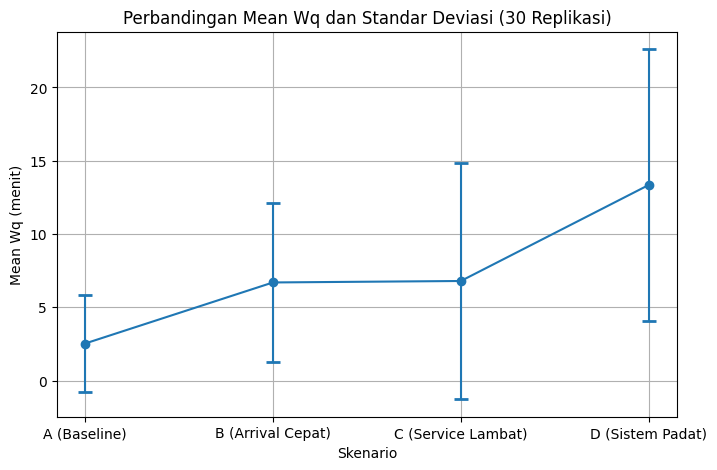

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_queue(lam=1/5, mu=1/3, sim_time=60, seed=42):
    rng = np.random.default_rng(seed)
    arrivals = []
    t = 0
    while True:
        t += rng.exponential(1 / lam)
        if t > sim_time:
            break
        arrivals.append(t)

    free = 0
    waits = []
    services = []
    for a in arrivals:
        st = rng.exponential(1 / mu)
        start = max(a, free)
        waits.append(start - a)
        services.append(st)
        free = start + st

    return np.array(arrivals), np.array(waits), np.array(services)

scenarios = {
    'A (Baseline)': {'interarrival': 5.0, 'service': 3.0},
    'B (Arrival Cepat)': {'interarrival': 3.0, 'service': 3.0},
    'C (Service Lambat)': {'interarrival': 5.0, 'service': 4.5},
    'D (Sistem Padat)': {'interarrival': 3.0, 'service': 4.0}
}

n_replications = 30
summary_mean_wq = []
summary_std_wq = []
labels = []

print(f"{'Skenario':<20} | {'Mean Wq':<10} | {'Max Wq':<10} | {'Std Wq':<10}")
print("-" * 58)

for name, params in scenarios.items():
    lam = 1.0 / params['interarrival']
    mu = 1.0 / params['service']

    rep_means = []
    rep_maxs = []

    for rep in range(n_replications):
        a, w, s = simulate_queue(lam=lam, mu=mu, sim_time=60, seed=42 + rep)
        if len(w) > 0:
            rep_means.append(w.mean())
            rep_maxs.append(w.max())
        else:
            rep_means.append(0.0)
            rep_maxs.append(0.0)

    mean_wq = np.mean(rep_means)
    max_wq = np.mean(rep_maxs)
    std_wq = np.std(rep_means)

    summary_mean_wq.append(mean_wq)
    summary_std_wq.append(std_wq)
    labels.append(name)

    print(f"{name:<20} | {mean_wq:<10.4f} | {max_wq:<10.4f} | {std_wq:<10.4f}")

plt.figure(figsize=(8, 5))
plt.errorbar(labels, summary_mean_wq, yerr=summary_std_wq, fmt='o-', capsize=5, capthick=2)
plt.xlabel("Skenario")
plt.ylabel("Mean Wq (menit)")
plt.title("Perbandingan Mean Wq dan Standar Deviasi (30 Replikasi)")
plt.grid(True)
plt.show()

### Analisa

Hasil percobaan menunjukkan bahwa peningkatan laju kedatangan (arrival rate) dan waktu pelayanan (service time) berbanding lurus dengan peningkatan waktu tunggu antrean ($W_q$). Ketika laju kedatangan mendekati atau melampaui kapasitas pelayanan ($\lambda \ge \mu$), seperti pada Skenario D, terjadi akumulasi antrean yang signifikan yang ditunjukkan oleh melonjaknya nilai Mean $W_q$, Max $W_q$, serta standar deviasi ($Std\ W_q$). Variansi ($Std\ W_q$) yang makin tinggi menandakan bahwa sistem semakin tidak stabil saat beban kerja meningkat.

### 4.3 Pengembangan Dua Kasir

Modifikasi model menjadi dua server/kasir. Bandingkan $c=1$ dan $c=2$ pada parameter yang sama.

In [ ]:
# Kerangka logika:
server_free = [0.0, 0.0]
server_id = np.argmin(server_free)
start = max(arrival_time, server_free[server_id])
server_free[server_id] = start + service_time

*Analisis:* Bagaimana $W_q$ berubah ketika jumlah server bertambah? Bagaimana perilakunya saat arrival rate tinggi?

In [ ]:
# Pengembangan Dua Kasir

import numpy as np
import matplotlib.pyplot as plt

def simulate_queue_multi(c=1, lam=1/5, mu=1/3, sim_time=60, seed=42):
    rng = np.random.default_rng(seed)
    arrivals = []
    t = 0
    while True:
        t += rng.exponential(1 / lam)
        if t > sim_time:
            break
        arrivals.append(t)

    server_free = [0.0] * c
    waits = []
    services = []
    for a in arrivals:
        st = rng.exponential(1 / mu)
        # Pilih server/kasir yang paling awal bebas
        server_id = np.argmin(server_free)
        start = max(a, server_free[server_id])
        waits.append(start - a)
        services.append(st)
        server_free[server_id] = start + st

    return np.array(arrivals), np.array(waits), np.array(services)

scenarios = {
    'A (Baseline)': {'interarrival': 5.0, 'service': 3.0},
    'B (Arrival Cepat)': {'interarrival': 3.0, 'service': 3.0},
    'C (Service Lambat)': {'interarrival': 5.0, 'service': 4.5},
    'D (Sistem Padat)': {'interarrival': 3.0, 'service': 4.0}
}

n_replications = 30

print(f"{'Skenario':<20} | {'Mean Wq (c=1)':<15} | {'Mean Wq (c=2)':<15} | {'Pengurangan (%)':<15}")
print("-" * 72)

for name, params in scenarios.items():
    lam = 1.0 / params['interarrival']
    mu = 1.0 / params['service']

    means_c1 = []
    means_c2 = []

    for rep in range(n_replications):
        seed = 42 + rep
        _, w1, _ = simulate_queue_multi(c=1, lam=lam, mu=mu, sim_time=60, seed=seed)
        _, w2, _ = simulate_queue_multi(c=2, lam=lam, mu=mu, sim_time=60, seed=seed)

        means_c1.append(w1.mean() if len(w1) > 0 else 0.0)
        means_c2.append(w2.mean() if len(w2) > 0 else 0.0)

    mean1 = np.mean(means_c1)
    mean2 = np.mean(means_c2)
    reduction = ((mean1 - mean2) / mean1 * 100) if mean1 > 0 else 0.0

    print(f"{name:<20} | {mean1:<15.4f} | {mean2:<15.4f} | {reduction:<15.2f}%")

Skenario             | Mean Wq (c=1)   | Mean Wq (c=2)   | Pengurangan (%)
------------------------------------------------------------------------
A (Baseline)         | 2.5277          | 0.1641          | 93.51          %
B (Arrival Cepat)    | 6.6931          | 0.5410          | 91.92          %
C (Service Lambat)   | 6.7924          | 0.5922          | 91.28          %
D (Sistem Padat)     | 13.3427         | 1.3893          | 89.59          %


### Analisa

Penambahan jumlah kasir dari $c=1$ menjadi $c=2$ secara signifikan menurunkan rata-rata waktu tunggu antrean ($W_q$) pada seluruh skenario. Penurunan ini paling terasa pada skenario dengan beban tinggi/sistem padat (Skenario B, C, dan D), karena keberadaan kasir kedua membagi beban kedatangan sehingga antrean terurai jauh lebih cepat dan mencegah penumpukan pelanggan di lokasi pelayanan.

### Analisa v2 (use this)
### Analisis: Bagaimana  Wq  berubah ketika jumlah server bertambah? Bagaimana perilakunya saat arrival rate tinggi?

Ketika jumlah server bertambah dari $c=1$ menjadi $c=2$, nilai $W_q$ (rata-rata waktu tunggu antrean) menurun secara drastis pada seluruh skenario karena kapasitas pelayanan total sistem meningkat dua kali lipat ($c\cdot\mu$). Saat arrival rate ($\lambda$) tinggi (seperti pada Skenario B dan D), sistem $c=1$ mengalami bottleneck dan akumulasi antrean secara eksponensial karena $\lambda$ mendekati atau melebihi $\mu$. Sebaliknya, pada sistem $c=2$ dengan arrival rate tinggi, antrean tetap stabil dan waktu tunggu terdistribusi secara seimbang karena kedatangan pelanggan dapat langsung ditangani oleh server yang sedang kosong.

## 5. System Dynamics (SD)

System Dynamics fokus pada perilaku sistem dari waktu ke waktu dengan stock, flow, feedback, dan delay. Berbeda dari DES yang event-driven, SD bersifat time-driven.

Persamaan materi: $\frac{dP}{dt} = \text{birth\_rate} \times P - \text{death\_rate} \times P$

### 5.1 Program Pertumbuhan Populasi

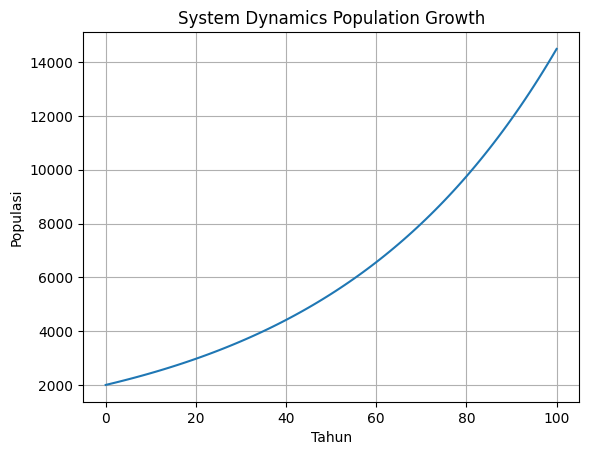

Populasi akhir: 14489.292236504665


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def growth(P0=2000, birth_rate=0.02, death_rate=0, years=100):
    t = np.arange(0, years + 1)
    P = np.zeros(len(t))
    P[0] = P0
    for i in range(1, len(t)):
        P[i] = P[i-1] + (birth_rate - death_rate) * P[i-1]
    return t, P

t, P = growth()
plt.plot(t, P)
plt.xlabel("Tahun")
plt.ylabel("Populasi")
plt.title("System Dynamics Population Growth")
plt.grid(True)
plt.show()
print("Populasi akhir:", P[-1])

### 5.2 Skenario

| Skenario | $P_0$ | Birth | Death |
| --- | --- | --- | --- |
| A | 2000 | 2% | 0% |
| B | 2000 | 3% | 0% |
| C | 2000 | 2% | 1% |
| D | 2000 | 2% | 2% |
| E | 2000 | 4% | 1% |

1. Bandingkan populasi akhir.
2. Plot semua skenario.
3. Jelaskan birth/death sebagai flow.
4. Identifikasi kondisi populasi tumbuh, konstan, dan turun.

Skenario                  | Populasi Akhir (Tahun 100)
-----------------------------------------------------
A (Birth 2%, Death 0%)    | 14489.29                 
B (Birth 3%, Death 0%)    | 38437.26                 
C (Birth 2%, Death 1%)    | 5409.63                  
D (Birth 2%, Death 2%)    | 2000.00                  
E (Birth 4%, Death 1%)    | 38437.26                 


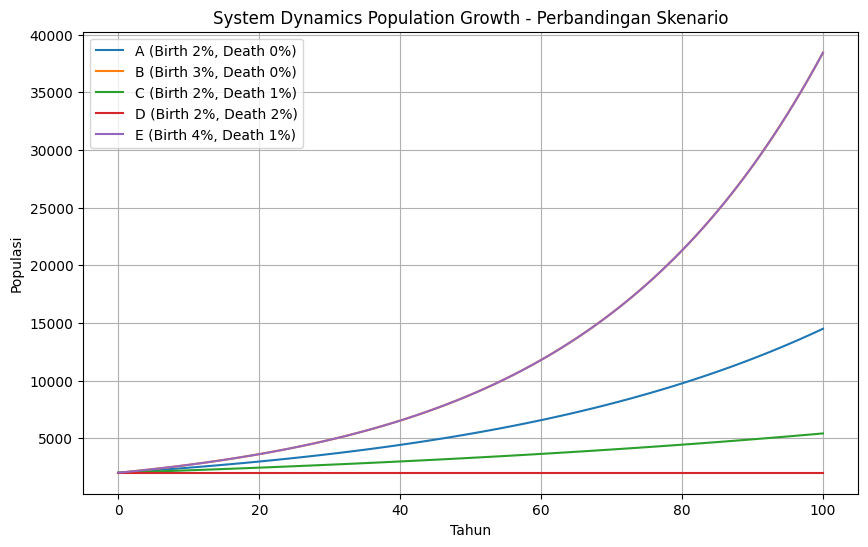

In [ ]:
# Skenario

import numpy as np
import matplotlib.pyplot as plt

def growth(P0=2000, birth_rate=0.02, death_rate=0.0, years=100):
    t = np.arange(0, years + 1)
    P = np.zeros(len(t))
    P[0] = P0
    for i in range(1, len(t)):
        P[i] = P[i-1] + (birth_rate - death_rate) * P[i-1]
    return t, P

scenarios = {
    'A (Birth 2%, Death 0%)': {'P0': 2000, 'b': 0.02, 'd': 0.00},
    'B (Birth 3%, Death 0%)': {'P0': 2000, 'b': 0.03, 'd': 0.00},
    'C (Birth 2%, Death 1%)': {'P0': 2000, 'b': 0.02, 'd': 0.01},
    'D (Birth 2%, Death 2%)': {'P0': 2000, 'b': 0.02, 'd': 0.02},
    'E (Birth 4%, Death 1%)': {'P0': 2000, 'b': 0.04, 'd': 0.01}
}

plt.figure(figsize=(10, 6))

print(f"{'Skenario':<25} | {'Populasi Akhir (Tahun 100)':<25}")
print("-" * 53)

for name, params in scenarios.items():
    t, P = growth(P0=params['P0'], birth_rate=params['b'], death_rate=params['d'])
    print(f"{name:<25} | {P[-1]:<25.2f}")
    plt.plot(t, P, label=name)

plt.xlabel("Tahun")
plt.ylabel("Populasi")
plt.title("System Dynamics Population Growth - Perbandingan Skenario")
plt.grid(True)
plt.legend()
plt.show()

1. Bandingkan populasi akhir.
2. Plot semua skenario.
3. Jelaskan birth/death sebagai flow.
4. Identifikasi kondisi populasi tumbuh, konstan, dan turun.


### Analisa

Hasil percobaan menunjukkan bahwa Skenario B dan E menghasilkan populasi akhir tertinggi yang identik ($38.437,00$) karena laju pertumbuhan bersih keduanya sama, yaitu $r = b - d = 3\%$ per tahun. Skenario D menghasilkan populasi yang konstan di angka $2.000$ karena $r = 0\%$.

### Jelaskan birth/death sebagai flow.

Dalam System Dynamics, Birth berfungsi sebagai Inflow (aliran masuk yang menambah jumlah Stock populasi), sedangkan Death berfungsi sebagai Outflow (aliran keluar yang mengurangi Stock populasi). Laju perubahan stok populasi ditentukan secara langsung oleh selisih nilai kedua Flow tersebut ($\frac{dP}{dt} = \text{Inflow} - \text{Outflow}$).

### Identifikasi kondisi populasi tumbuh, konstan, dan turun.

Kondisi Populasi:

- Tumbuh: Terjadi saat $\text{birth\_rate} > \text{death\_rate}$ ($r > 0$), seperti pada Skenario A, B, C, dan E.
- Konstan: Terjadi saat $\text{birth\_rate} = \text{death\_rate}$ ($r = 0$), seperti pada Skenario D.
- Turun: Terjadi saat $\text{birth\_rate} < \text{death\_rate}$ ($r < 0$), di mana populasi akan mengalami eksponensial menurun dari waktu ke waktu.   

### 5.3 Pengembangan Logistic Growth

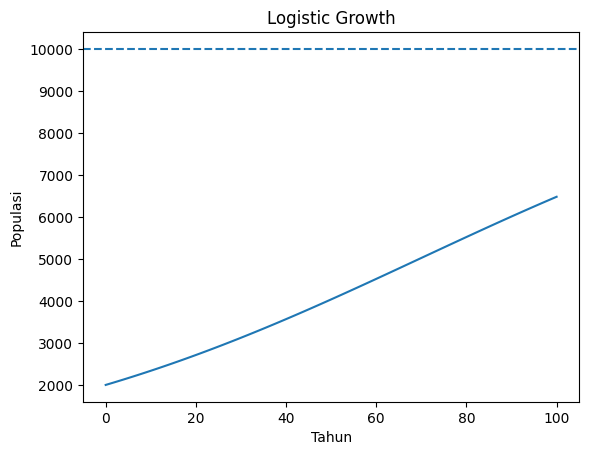

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

P0 = 2000
r = 0.02
K = 10000
t = np.arange(101)
P = np.zeros(101)
P[0] = P0

for i in range(1, 101):
    P[i] = P[i-1] + r * P[i-1] * (1 - P[i-1] / K)

plt.plot(t, P)
plt.axhline(K, linestyle="--")
plt.xlabel("Tahun")
plt.ylabel("Populasi")
plt.title("Logistic Growth")
plt.show()

### Analisa

Berbeda dari pertumbuhan eksponensial yang meningkat tanpa batas, model *Logistic Growth* membatasi pertumbuhan populasi melalui batas daya dukung lingkungan (*Carrying Capacity*, $K = 10.000$) sehingga membentuk pola kurva Sigmoid (huruf S). Pada tahap awal, populasi tumbuh cepat karena persaingan sumber daya masih rendah, namun seiring bertambahnya populasi mendekati nilai $K$ ($P \to K$), laju pertumbuhan melambat secara otomatis dan populasi berkonvergensi secara stabil menuju batas maksimum tersebut.

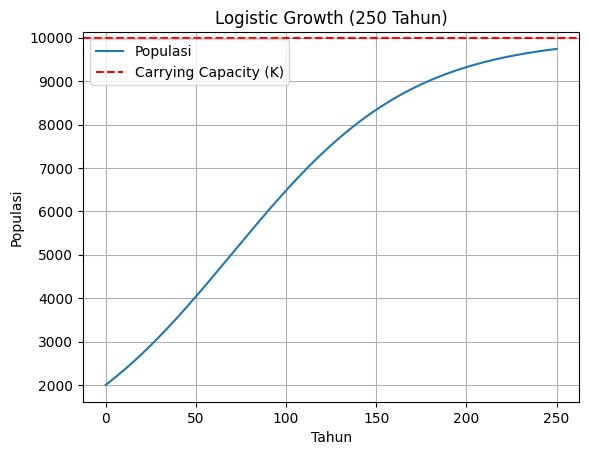

In [ ]:
# Modifikasi

import numpy as np
import matplotlib.pyplot as plt

P0 = 2000
r = 0.02
K = 10000
years = 250  # Diperpanjang dari 100 ke 250 tahun
t = np.arange(years + 1)
P = np.zeros(years + 1)
P[0] = P0

for i in range(1, years + 1):
    P[i] = P[i-1] + r * P[i-1] * (1 - P[i-1] / K)

plt.plot(t, P, label="Populasi")
plt.axhline(K, color="red", linestyle="--", label="Carrying Capacity (K)")
plt.xlabel("Tahun")
plt.ylabel("Populasi")
plt.title("Logistic Growth (250 Tahun)")
plt.grid(True)
plt.legend()
plt.show()

## 6. Agent-Based Simulation (ABS)

ABS memodelkan sistem sebagai kumpulan agen otonom. Agen memiliki atribut, aturan perilaku, dan interaksi. Materi menekankan heterogenitas, interaksi, adaptasi, dan *emergence*.

### 6.1 Mini Epidemi - 20 Orang

Sesuai materi: agen berada pada state sehat (S), terinfeksi (I), atau sembuh (R); peluang penularan 30% ketika agen sehat bertemu agen terinfeksi; agen terinfeksi sembuh setelah 3 langkah.

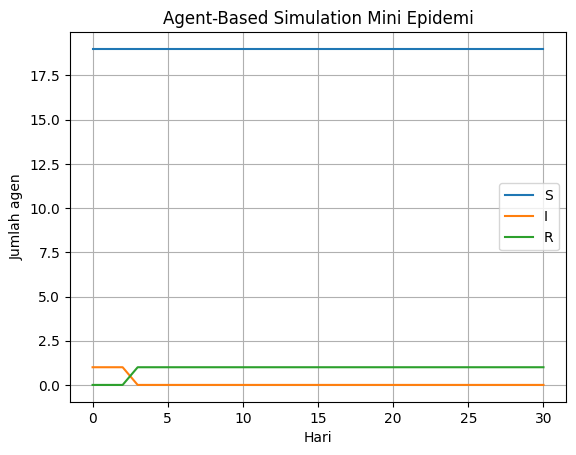

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def epidemic(n=20, days=30, p=0.30, recovery=3, seed=42):
    rng = np.random.default_rng(seed)
    state = np.array(["S"] * n)
    age = np.zeros(n, dtype=int)
    state[0] = "I"
    hist = [state.copy()]

    for day in range(days):
        new = state.copy()
        for i in range(n):
            if state[i] == "I":
                for j in [i - 1, i + 1]:
                    if 0 <= j < n and state[j] == "S" and rng.random() < p:
                        new[j] = "I"
        for i in range(n):
            if state[i] == "I" or new[i] == "I":
                age[i] += 1
            if new[i] == "I" and age[i] >= recovery:
                new[i] = "R"
        state = new
        hist.append(state.copy())

    return np.array(hist)

H = epidemic()
S = (H == "S").sum(axis=1)
I = (H == "I").sum(axis=1)
R = (H == "R").sum(axis=1)

plt.plot(S, label="S")
plt.plot(I, label="I")
plt.plot(R, label="R")
plt.xlabel("Hari")
plt.ylabel("Jumlah agen")
plt.title("Agent-Based Simulation Mini Epidemi")
plt.legend()
plt.grid(True)
plt.show()

### 6.2 Skenario ABS

| Skenario | Populasi | $p$ infeksi | Recovery |
| --- | --- | --- | --- |
| A - Low | 20 | 0.10 | 3 hari |
| B - Baseline | 20 | 0.30 | 3 hari |
| C - High | 20 | 0.60 | 3 hari |
| D - Slow recovery | 20 | 0.30 | 6 hari |
| E - Larger | 100 | 0.30 | 3 hari |

1. Bandingkan grafik S, I, R.
2. Cari peak infected dan hari peak.
3. Analisis pengaruh probabilitas penularan.
4. Analisis pengaruh waktu pemulihan.
5. Jelaskan *emergence*.

Skenario             | Peak Infected   | Hari Peak 
--------------------------------------------------
A - Low              | 1               | Hari ke-0
B - Baseline         | 1               | Hari ke-0
C - High             | 2               | Hari ke-2
D - Slow recovery    | 2               | Hari ke-5
E - Larger           | 1               | Hari ke-0


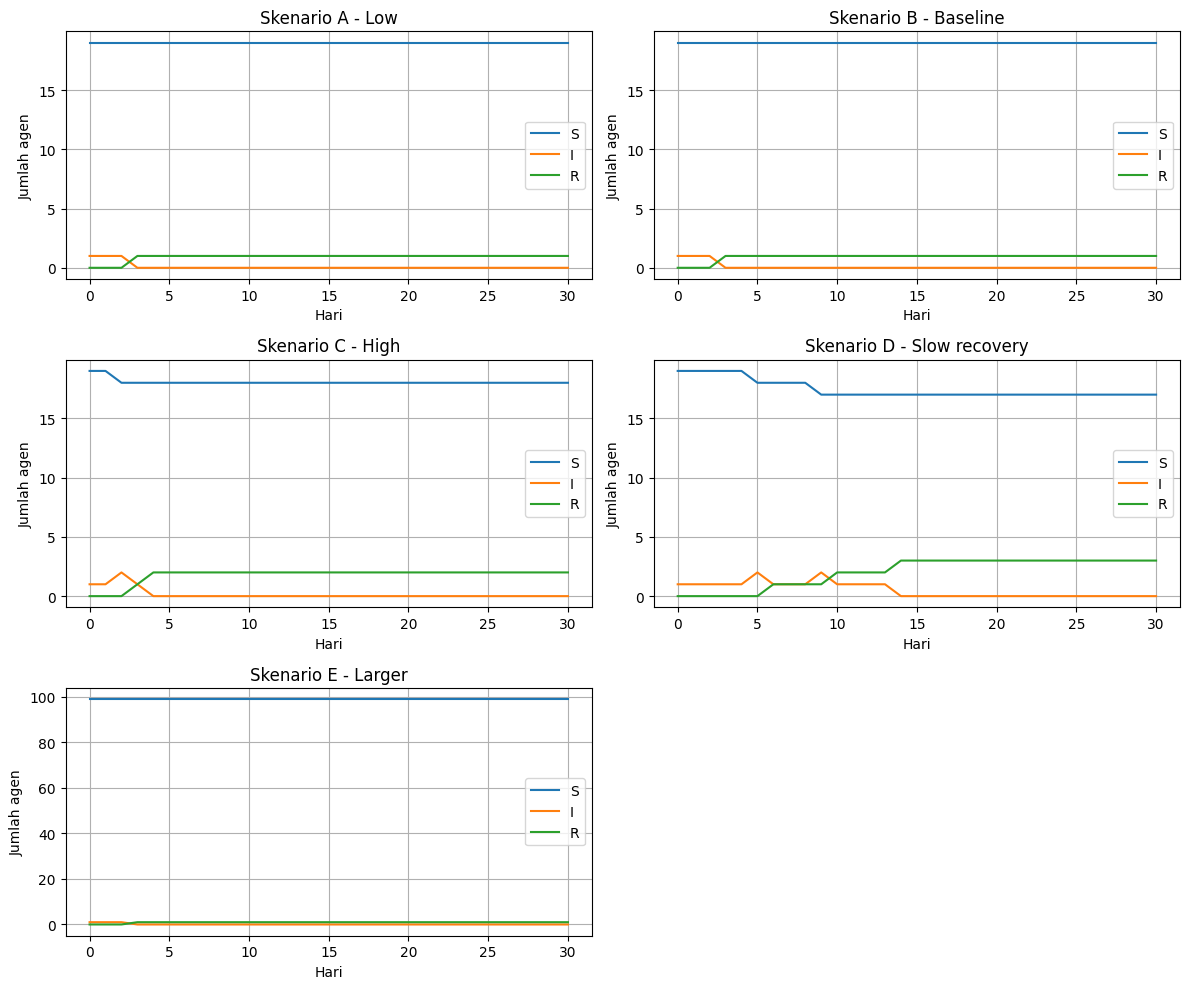

In [ ]:
# Skenario

import numpy as np
import matplotlib.pyplot as plt

def epidemic(n=20, days=30, p=0.30, recovery=3, seed=42):
    rng = np.random.default_rng(seed)
    state = np.array(["S"] * n)
    age = np.zeros(n, dtype=int)
    state[0] = "I"
    hist = [state.copy()]

    for day in range(days):
        new = state.copy()
        for i in range(n):
            if state[i] == "I":
                for j in [i - 1, i + 1]:
                    if 0 <= j < n and state[j] == "S" and rng.random() < p:
                        new[j] = "I"
        for i in range(n):
            if state[i] == "I" or new[i] == "I":
                age[i] += 1
            if new[i] == "I" and age[i] >= recovery:
                new[i] = "R"
        state = new
        hist.append(state.copy())

    return np.array(hist)

scenarios = {
    'A - Low': {'n': 20, 'p': 0.10, 'recovery': 3},
    'B - Baseline': {'n': 20, 'p': 0.30, 'recovery': 3},
    'C - High': {'n': 20, 'p': 0.60, 'recovery': 3},
    'D - Slow recovery': {'n': 20, 'p': 0.30, 'recovery': 6},
    'E - Larger': {'n': 100, 'p': 0.30, 'recovery': 3}
}

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

print(f"{'Skenario':<20} | {'Peak Infected':<15} | {'Hari Peak':<10}")
print("-" * 50)

for idx, (name, params) in enumerate(scenarios.items()):
    H = epidemic(n=params['n'], days=30, p=params['p'], recovery=params['recovery'], seed=42)
    S = (H == "S").sum(axis=1)
    I = (H == "I").sum(axis=1)
    R = (H == "R").sum(axis=1)

    peak_i = I.max()
    peak_day = I.argmax()

    print(f"{name:<20} | {peak_i:<15} | Hari ke-{peak_day}")

    ax = axes[idx]
    ax.plot(S, label="S")
    ax.plot(I, label="I")
    ax.plot(R, label="R")
    ax.set_title(f"Skenario {name}")
    ax.set_xlabel("Hari")
    ax.set_ylabel("Jumlah agen")
    ax.legend()
    ax.grid(True)

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

### Analisa

Hasil percobaan menunjukkan bahwa pada skenario A, B, dan E, penyakit langsung padam pada hari pertama tanpa sempat menular ke agen lain (Peak Infected $= 1$). Skenario C dan D menunjukkan penularan terbatas (Peak Infected $= 2$), di mana agen pertama berhasil menularkan penyakit ke tetangganya sebelum sembuh.

### Pengaruh probabilitas penularan ($p$)

Peningkatan probabilitas penularan dari $0.10$/$0.30$ (Skenario A dan B) menjadi $0.60$ (Skenario C) membuka peluang terjadinya transmisi antar-agen, ditandai dengan naiknya puncak infeksi dari $1$ menjadi $2$.

### Pengaruh waktu pemulihan (Recovery)

Waktu pemulihan yang lebih lama ($6$ hari pada Skenario D dibanding $3$ hari pada Skenario B) memperpanjang masa infeksi agen pertama, sehingga memberi lebih banyak kesempatan bagi agen tersebut untuk menularkan penyakit hingga mencapai Peak Infected $= 2$ pada hari ke-5.

### Konsep Emergence

Fenomena wabah makro (puncak epidemi populasi) muncul secara alami dari interaksi individual diskret (micro-level) antar-agen bertetangga berdasarkan aturan probabilistik penularan dan durasi pemulihan sederhana, tanpa adanya aturan eksplisit yang mengatur bentuk kurva epidemi secara keseluruhan.

## 7. Sesi E - Monte Carlo Epidemi

Materi: populasi 100 orang, awal 1 terinfeksi, probabilitas menular 0.2, 30 hari, 1.000 pengulangan, dan pertanyaan peluang $>50\%$ populasi terinfeksi pada hari ke-15.

P(I hari-15 > 50%) = 1.0


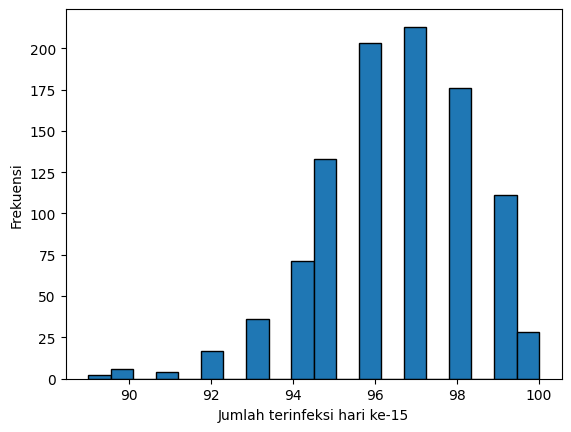

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def trial(n=100, days=30, p=0.2, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    infected = 1
    h = [infected]
    for _ in range(days):
        new = rng.binomial(n - infected, p)
        infected = min(n, infected + new)
        h.append(infected)
    return h

rng = np.random.default_rng(42)
N = 1000
results = np.array([trial(rng=rng) for _ in range(N)])
day15 = results[:, 15]
prob = np.mean(day15 > 50)

print("P(I hari-15 > 50%) =", prob)

plt.hist(day15, bins=20, edgecolor="black")
plt.xlabel("Jumlah terinfeksi hari ke-15")
plt.ylabel("Frekuensi")
plt.show()

### Analisa

Hasil simulasi Monte Carlo menunjukkan bahwa peluang jumlah populasi terinfeksi melebihi $50\%$ pada hari ke-15 bernilai $1.0$ ($100\%$). Pola pertumbuhan eksponensial tanpa mekanisme pemulihan membuat penyebaran infeksi berlangsung sangat masif, di mana seluruh $1.000$ pengulangan menghasilkan antara 89 hingga 100 individu terinfeksi pada hari ke-15.